# Unit 4 — Feature Extraction and Image Matching (Task 2)

**What this notebook does**

1. Extract and visualise **HOG** (Histogram of Oriented Gradients) features.
2. Detect **SIFT** keypoints and compute their descriptors.
3. **Match** SIFT features between two photos of the same object/scene.
4. Repeat the matching after **rotating** and **resizing** one photo.
5. Compare the matching quality in a table.

**Input:** `data/photo1.jpeg` and `data/photo2.jpeg` – two photos of the **same** object or scene, taken from a slightly different angle or distance.

**Output:** every result image is saved in `outputs/unit4/`.

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure

OUT = "outputs/unit4"
os.makedirs(OUT, exist_ok=True)


def load_image(path, width=800):
    # Read a photo and shrink it to 800 pixels wide (keeps the shape the same)
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read {path}. Put your photo in the data folder.")
    h, w = img.shape[:2]
    if w > width:
        img = cv2.resize(img, (width, int(h * width / w)))
    return img


def show(images, titles, cols=2):
    # Show many images in a grid. OpenCV stores colour as BGR, matplotlib wants RGB.
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(7 * cols, 5 * rows))
    for i in range(len(images)):
        plt.subplot(rows, cols, i + 1)
        if images[i].ndim == 2:
            plt.imshow(images[i], cmap="gray")
        else:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(titles[i])
        plt.axis("off")
    plt.tight_layout()
    plt.show()


def save(name, img):
    cv2.imwrite(os.path.join(OUT, name), img)

Photo 1 size: (1066, 800, 3)
Photo 2 size: (1066, 800, 3)


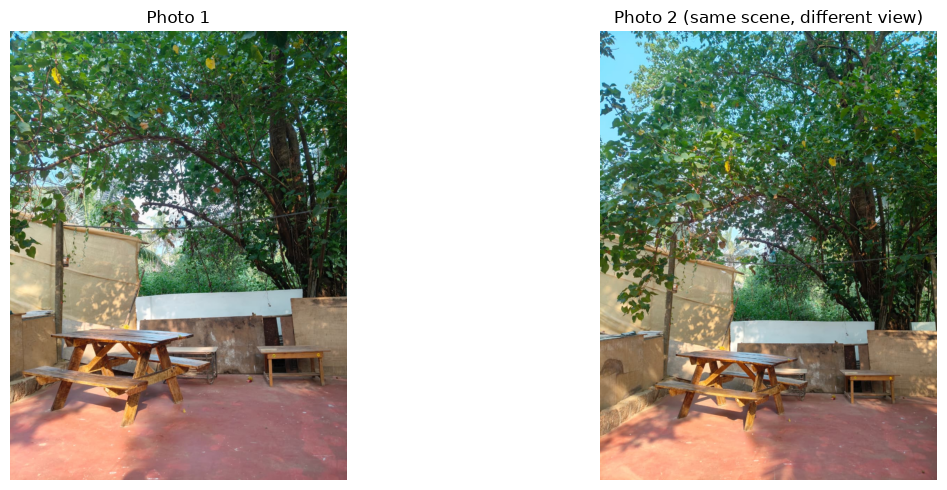

In [2]:
img1 = load_image("data/photo1.jpeg")
img2 = load_image("data/photo2.jpeg")
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

print("Photo 1 size:", img1.shape)
print("Photo 2 size:", img2.shape)
show([img1, img2], ["Photo 1", "Photo 2 (same scene, different view)"])

---
## 1. HOG — Histogram of Oriented Gradients

HOG describes the **shape** of things using the direction of edges.

1. For every pixel, find the *gradient*: in which direction and how strongly the brightness changes.
2. Split the image into small **cells** (here 16 × 16 pixels).
3. In every cell, make a **histogram** of the edge directions using 9 bins (0°, 20°, 40° … 160°). Strong edges add more votes.
4. Group 2 × 2 cells into a **block** and normalise it, so that lighting changes do not matter much.
5. Join all the block histograms into one long list of numbers – the **HOG feature vector**.

In the picture, every cell shows little lines pointing in its main edge directions. Brighter line = stronger edge in that direction.

Photo 1 HOG feature vector length: 114660
Photo 2 HOG feature vector length: 114660
First 10 HOG values of photo 1: [0.268 0.133 0.176 0.09  0.231 0.157 0.268 0.268 0.268 0.086]


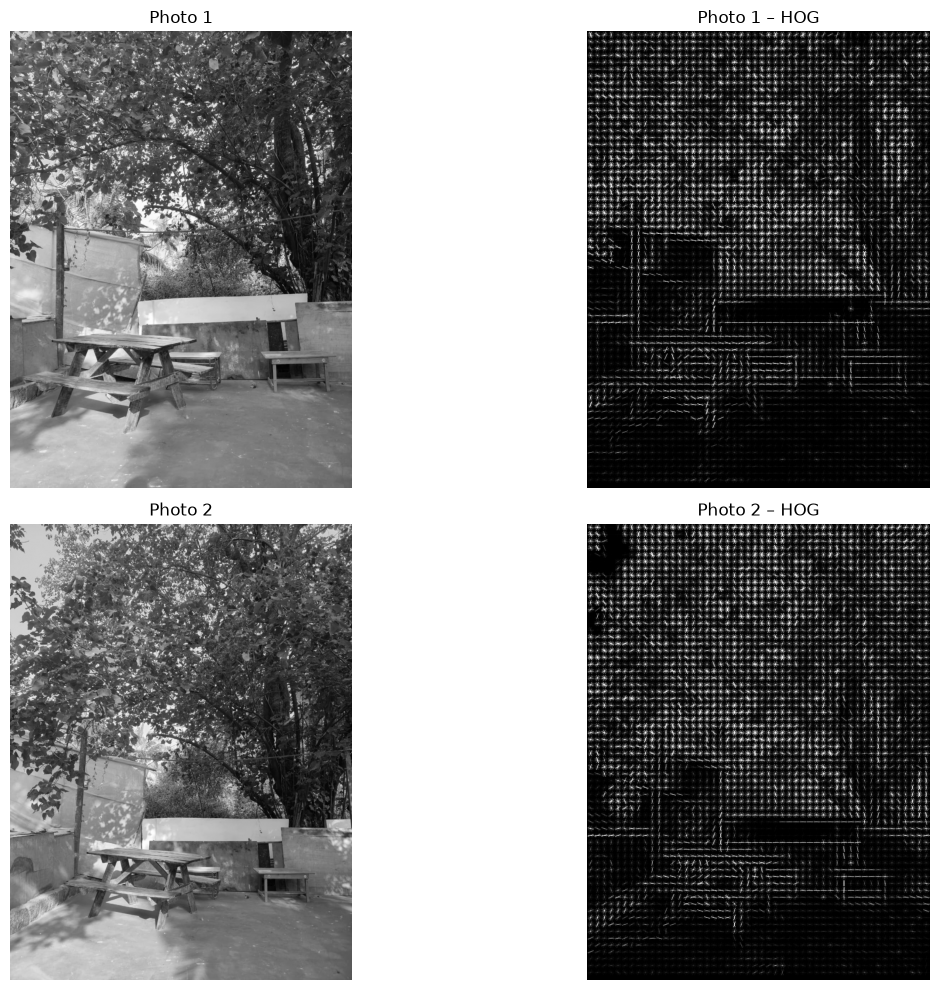

In [3]:
def get_hog(gray):
    features, hog_image = hog(gray,
                              orientations=9,            # 9 direction bins
                              pixels_per_cell=(16, 16),  # cell size
                              cells_per_block=(2, 2),    # block = 2 x 2 cells
                              visualize=True)            # also return a picture
    # The HOG picture is very dark, so stretch its brightness to 0..255 for display
    hog_image = exposure.rescale_intensity(hog_image, in_range=(0, 10), out_range=(0, 255))
    return features, hog_image.astype(np.uint8)


features1, hog_img1 = get_hog(gray1)
features2, hog_img2 = get_hog(gray2)

print("Photo 1 HOG feature vector length:", len(features1))
print("Photo 2 HOG feature vector length:", len(features2))
print("First 10 HOG values of photo 1:", np.round(features1[:10], 3))

show([gray1, hog_img1, gray2, hog_img2],
     ["Photo 1", "Photo 1 – HOG", "Photo 2", "Photo 2 – HOG"])
save("01_hog_photo1.jpg", hog_img1)
save("01_hog_photo2.jpg", hog_img2)

---
## 2. SIFT — keypoints and descriptors

**SIFT (Scale-Invariant Feature Transform)** finds special points (**keypoints**) such as corners and blobs that can be found again even if the image is **rotated, resized** or the lighting changes.

For every keypoint SIFT gives:
* **position** (x, y), **size** (scale) and **orientation** (main direction) – drawn as a circle with a line,
* a **descriptor** – a list of **128 numbers** that describes the area around the point (4 × 4 small regions × 8 direction bins = 128).

Photo 1: 8474 keypoints, descriptor array shape: (8474, 128)
Photo 2: 10222 keypoints, descriptor array shape: (10222, 128)

Example keypoint -> position: [  2.5 665.8]  size: 2.6  angle: 324.0
Its descriptor (first 16 of 128 numbers): [ 0.  0.  0.  0.  0.  0.  0.  0.  0. 19.  4.  0.  0.  0.  0.  0.]


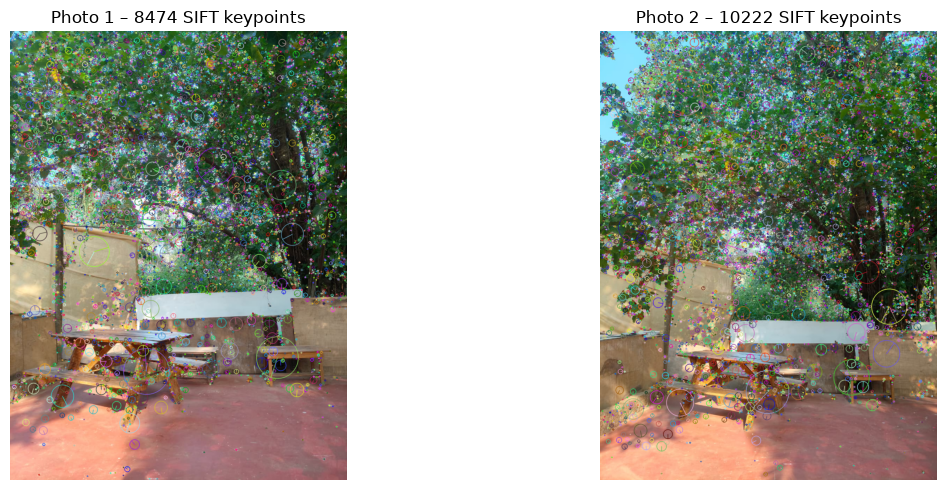

In [4]:
sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

print("Photo 1:", len(kp1), "keypoints, descriptor array shape:", des1.shape)
print("Photo 2:", len(kp2), "keypoints, descriptor array shape:", des2.shape)

k = kp1[0]
print("\nExample keypoint -> position:", np.round(k.pt, 1), " size:", round(k.size, 1), " angle:", round(k.angle, 1))
print("Its descriptor (first 16 of 128 numbers):", des1[0][:16])

# RICH_KEYPOINTS draws each keypoint as a circle (size) with a line (orientation)
kp_img1 = cv2.drawKeypoints(img1, kp1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
kp_img2 = cv2.drawKeypoints(img2, kp2, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

show([kp_img1, kp_img2], [f"Photo 1 – {len(kp1)} SIFT keypoints", f"Photo 2 – {len(kp2)} SIFT keypoints"])
save("02_sift_keypoints_photo1.jpg", kp_img1)
save("02_sift_keypoints_photo2.jpg", kp_img2)

---
## 3. Match SIFT features between the two photos

1. **Brute-Force matcher** – for every descriptor in photo A, compare it with *every* descriptor in photo B using the Euclidean (straight-line) distance. Small distance = similar.
2. We take the **2 closest** matches for every point (`knnMatch` with `k=2`).
3. **Lowe's ratio test** – keep a match only if the best match is clearly better than the second best (`best < 0.75 × second best`). This throws away confusing matches, e.g. on repeated patterns.
4. **RANSAC** – checks which of the good matches agree with *one common* movement (a homography) between the photos. Matches that agree are called **inliers** (very likely correct). A high inlier percentage means good matching quality.

We put all of this in one function so we can reuse it for every experiment.

{'kp_a': 8474, 'kp_b': 10222, 'raw': 8474, 'good': 208, 'inliers': 104}


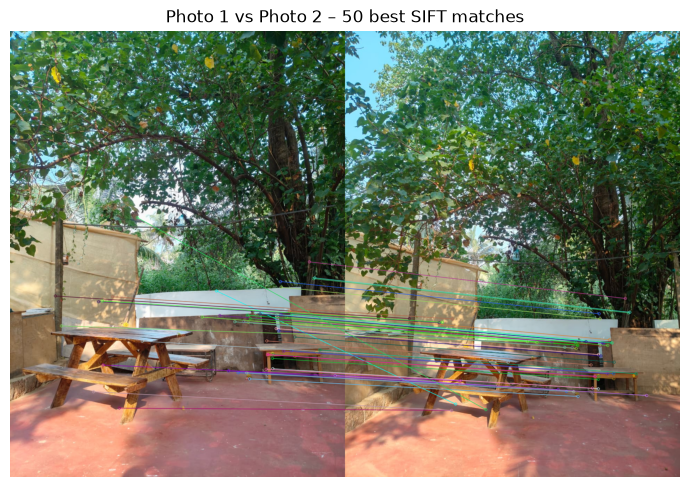

In [5]:
def match_images(img_a, img_b, ratio=0.75):
    gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
    gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)
    kp_a, des_a = sift.detectAndCompute(gray_a, None)
    kp_b, des_b = sift.detectAndCompute(gray_b, None)

    # 1-2. For every descriptor in A, find the 2 nearest descriptors in B
    matcher = cv2.BFMatcher(cv2.NORM_L2)
    pairs = matcher.knnMatch(des_a, des_b, k=2)

    # 3. Lowe's ratio test
    good = []
    for pair in pairs:
        if len(pair) == 2:
            best, second = pair
            if best.distance < ratio * second.distance:
                good.append(best)
    good = sorted(good, key=lambda m: m.distance)   # best matches first

    # 4. RANSAC: how many good matches agree with one geometric transformation?
    inliers = 0
    if len(good) >= 4:                               # a homography needs at least 4 points
        pts_a = np.float32([kp_a[m.queryIdx].pt for m in good])
        pts_b = np.float32([kp_b[m.trainIdx].pt for m in good])
        H, mask = cv2.findHomography(pts_a, pts_b, cv2.RANSAC, 5.0)
        if mask is not None:
            inliers = int(mask.sum())

    # Draw the 50 best matches as lines between the two images
    picture = cv2.drawMatches(img_a, kp_a, img_b, kp_b, good[:50], None,
                              flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    summary = {"kp_a": len(kp_a), "kp_b": len(kp_b), "raw": len(pairs),
               "good": len(good), "inliers": inliers}
    return summary, picture


summary, picture = match_images(img1, img2)
print(summary)
show([picture], ["Photo 1 vs Photo 2 – 50 best SIFT matches"], cols=1)
save("03_matches_photo1_photo2.jpg", picture)

---
## 4. Repeat matching after rotating and resizing

We change **photo 2** and match it with photo 1 again:

* rotated by 45° (`getRotationMatrix2D` + `warpAffine`; corners that leave the frame are cut off),
* resized to 50%,
* rotated by 90° **and** resized to 50% (both changes together).

If SIFT is really rotation- and scale-invariant, the number of good matches should stay reasonably high.

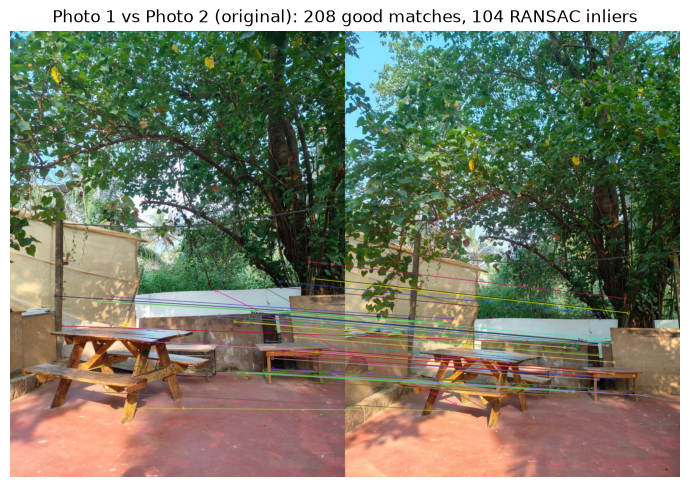

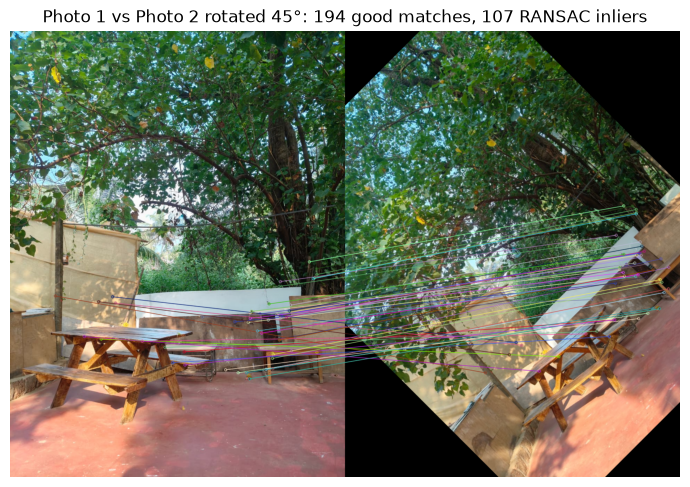

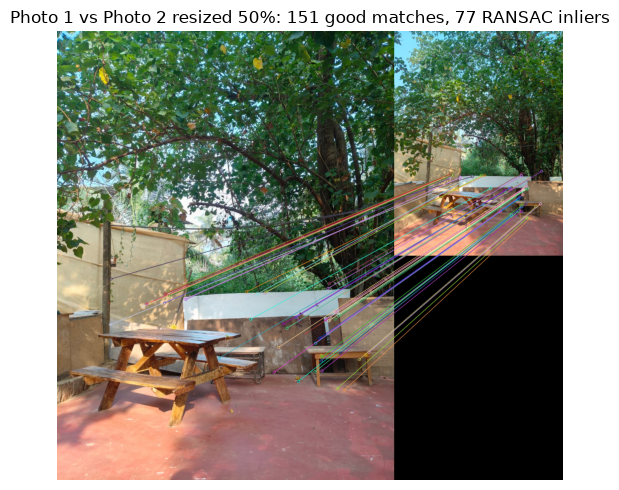

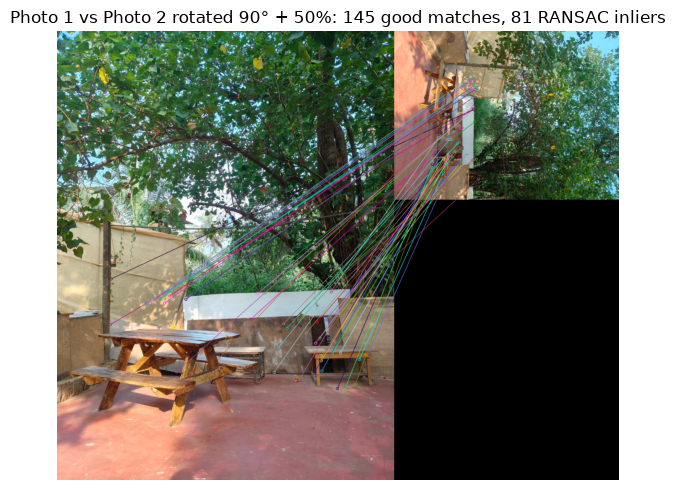

In [6]:
h, w = img2.shape[:2]
M = cv2.getRotationMatrix2D((w / 2, h / 2), 45, 1.0)      # centre, angle, scale
rotated_45 = cv2.warpAffine(img2, M, (w, h))
resized_50 = cv2.resize(img2, None, fx=0.5, fy=0.5)
rot90_small = cv2.resize(cv2.rotate(img2, cv2.ROTATE_90_CLOCKWISE), None, fx=0.5, fy=0.5)

experiments = {
    "Photo 1 vs Photo 2 (original)":         img2,
    "Photo 1 vs Photo 2 rotated 45°":        rotated_45,
    "Photo 1 vs Photo 2 resized 50%":        resized_50,
    "Photo 1 vs Photo 2 rotated 90° + 50%":  rot90_small,
}

table = []
for i, (name, changed) in enumerate(experiments.items()):
    s, pic = match_images(img1, changed)
    table.append((name, s))
    show([pic], [f"{name}: {s['good']} good matches, {s['inliers']} RANSAC inliers"], cols=1)
    save(f"04_matches_{i}.jpg", pic)

## 5. Compare the matching quality

* **Good matches** – matches that passed the ratio test.
* **Inliers** – good matches that also agree with one common transformation (RANSAC) → very likely correct.
* **Inlier %** = inliers ÷ good matches × 100. Higher = cleaner matching.

In [7]:
print("| Experiment | Keypoints (photo 1) | Keypoints (photo 2) | Good matches | RANSAC inliers | Inlier % |")
print("|---|---|---|---|---|---|")
for name, s in table:
    inlier_pct = 100 * s["inliers"] / max(s["good"], 1)    # max(...,1) avoids dividing by 0
    print(f"| {name} | {s['kp_a']} | {s['kp_b']} | {s['good']} | {s['inliers']} | {inlier_pct:.1f} |")

| Experiment | Keypoints (photo 1) | Keypoints (photo 2) | Good matches | RANSAC inliers | Inlier % |
|---|---|---|---|---|---|
| Photo 1 vs Photo 2 (original) | 8474 | 10222 | 208 | 104 | 50.0 |
| Photo 1 vs Photo 2 rotated 45° | 8474 | 9722 | 194 | 107 | 55.2 |
| Photo 1 vs Photo 2 resized 50% | 8474 | 2922 | 151 | 77 | 51.0 |
| Photo 1 vs Photo 2 rotated 90° + 50% | 8474 | 2932 | 145 | 81 | 55.9 |


**Observation** – *check against your own numbers and edit if needed*

* SIFT still finds many correct matches after **rotation** because every keypoint stores its own orientation and the descriptor is measured relative to it.
* After **resizing**, fewer keypoints are found (a smaller image has fewer details), so the number of matches drops, but the matches that remain are still mostly correct, because SIFT searches over many scales.
* The **inlier %** stays fairly high in all cases, which shows SIFT is robust to rotation and scale.
* **HOG** is different: it describes the whole image on a fixed grid. If the image rotates, the edge directions in every cell change, so HOG is **not** rotation-invariant. That is why HOG is used for *detecting* objects in an upright position (e.g. pedestrians), while SIFT is used for *matching* points between images.